# Pseudobulk with bixverse

## Intro

Single cell differential expression across conditions has a replication
problem. Five thousand monocytes from eight donors are eight observations,
not five thousand, and a test over cells pretends otherwise. Summing the
counts per donor and condition (pseudobulk) and running a bulk method on the
sums is the boring, honest fix, and in benchmarks it is also one of the best
performing ones ([Squair, et al.](https://doi.org/10.1038/s41467-021-25960-2)).

[bixverse](https://github.com/GregorLueg/bixverse-rs) does the single cell
side: QC, cell type labels, and the summing, straight off its on-disk store.
`edge_rs` does the bulk side. The hand-off is one NumPy array and a
transpose. This vignette runs it per cell type on the Kang PBMCs, with both
edgeR QL and limma-voom.

In [1]:
import tempfile
import timeit
from pathlib import Path

import bixverse as bv
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from bixverse.params import MinQualityParams

import edge_rs

## The data

[Kang, et al.](https://doi.org/10.1038/nbt.4042) pooled PBMCs from eight lupus
donors, split each sample in two and stimulated one half with IFN-beta.
Every donor contributes to both arms, which makes it a paired design. bixverse
downloads the h5ad, runs its QC and writes the store into a temporary
directory.

In [2]:
tempdir = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(
    Path(tempdir.name) / "kang",
    bv.io.download_kang_pbmc(),
    qc=MinQualityParams(
        min_unique_genes=200,
        min_lib_size=500,
        min_cells=20,
        target_size=1e4,
    ),
    verbose=False,
)

Drop the demultiplexing doublets and the cells without a cell type call.

In [3]:
obs = sc.obs(cols=["cell_idx", "multiplets", "cell"], filtered=True)

keep = obs.filter((pl.col("multiplets") == "singlet") & pl.col("cell").is_not_null())[
    "cell_idx"
]

sc.set_cells_to_keep(keep.to_numpy())

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpvy6macf1/kang',
  cells=28871 (kept 24562), genes=12526,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

## Pseudobulking

One pseudobulk sample per cell type, donor and condition. Build the groups
from the obs table with polars, then hand `get_pseudobulked()` a dict of
sample name to cell ids.

In [4]:
obs = sc.obs(filtered=True).with_columns(pl.col("cell", "ind", "stim").cast(pl.String))

groups = (
    obs.group_by("cell", "ind", "stim")
    .agg("cell_id", n_cells=pl.len())
    .sort("cell", "ind", "stim")
)

pb = bv.de.get_pseudobulked(
    sc,
    {
        f"{c}|{i}|{s}": cells
        for c, i, s, cells in groups.select(
            "cell", "ind", "stim", "cell_id"
        ).iter_rows()
    },
    verbose=False,
)

pb

PseudoBulked(n_samples=128, n_genes=12526, sparse=False)

`pb.counts` is samples x genes, the single cell orientation. `edge_rs` wants
genes x samples, so the hand-off is `pb.counts.T`. That is a view, not a
copy, and `edge_rs` deals with the memory layout on its side.

The sample table is just `groups` without the cell ids, in the same order as
the rows of the counts.

In [5]:
counts = pb.counts
assert isinstance(counts, np.ndarray)  # dense is the default return_format

meta = groups.drop("cell_id")

meta.pivot(on="stim", index="cell", values="n_cells", aggregate_function="min")

cell,ctrl,stim
str,u32,u32
"""B cells""",26,39
"""CD14+ Monocytes""",112,150
"""CD4 T cells""",158,186
"""CD8 T cells""",20,15
"""Dendritic cells""",8,14
"""FCGR3A+ Monocytes""",31,35
"""Megakaryocytes""",4,4
"""NK cells""",18,23


That is the smallest pseudobulk sample per cell type and arm. A sum over a
handful of cells is noisy, and megakaryocytes and dendritic cells get thin.
We stick to the abundant types here.

## One cell type

CD14+ monocytes first. The design blocks on the donor, which is what makes
it a paired test, and the coefficient of interest is `stim`.

In [6]:
rows = (meta["cell"] == "CD14+ Monocytes").to_numpy()
mono = meta.filter(rows)

donors = sorted(mono["ind"].unique())

design = pl.DataFrame(
    {
        "intercept": np.ones(mono.height),
        **{f"ind{d}": (mono["ind"] == d).cast(pl.Float64) for d in donors[1:]},
        "stim": (mono["stim"] == "stim").cast(pl.Float64),
    }
)

design.head()

intercept,ind1015,ind1016,ind1039,ind107,ind1244,ind1256,ind1488,stim
f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


The one-liners do filter, TMM, fit and test. They return the genes that
pass the filter, in input order.

In [7]:
ql = edge_rs.run_edger_ql(counts[rows].T, design, feature_ids=pb.gene_ids, coef="stim")
voom = edge_rs.run_limma_voom(
    counts[rows].T, design, feature_ids=pb.gene_ids, coef="stim"
)

ql.sort("p_value").head(10)

feature_id,log_fc,log_cpm,f_stat,p_value,fdr
str,f64,f64,f64,f64,f64
"""NCOA7""",6.718271,5.651145,606.363404,1.6111e-18,5.2568e-15
"""NEXN""",6.710897,6.183041,597.804352,2.0320e-18,5.2568e-15
"""GMPR""",7.049398,7.002385,820.914026,4.6559e-18,8.0298e-15
"""CD38""",7.240507,7.4469,846.473998,9.9471e-18,1.2867e-14
"""HESX1""",8.628006,6.753923,611.841979,4.0267e-17,4.1668e-14
"""NT5C3A""",5.833164,8.312303,1486.295948,4.8912e-17,4.2179e-14
"""IFITM1""",6.173227,6.303572,653.546866,1.3168e-16,9.7333e-14
"""NUPR1""",8.214368,6.325899,565.531583,2.3015e-16,1.4885e-13
"""SAMD4A""",5.918612,5.687085,444.364958,6.3510e-16,3.6511e-13


Fold changes of 2^6 and up with p-values below 1e-15: IFN-beta is about as
strong a perturbation as single cell data offers. The two methods side by
side:

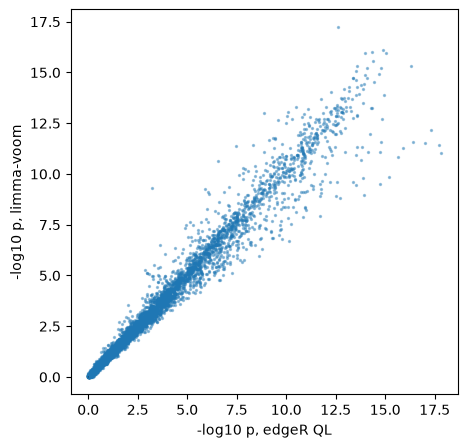

cor_log_fc,sig_ql,sig_voom
f64,u32,u32
0.997243,3170,3175


In [8]:
both = ql.join(voom, on="feature_id", suffix="_voom")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(-np.log10(both["p_value"]), -np.log10(both["p_value_voom"]), s=2, alpha=0.4)
lim = max(-np.log10(both["p_value"]).max(), -np.log10(both["p_value_voom"]).max())
ax.plot([0, lim], [0, lim], color="black", lw=0.5)
ax.set_xlabel("-log10 p, edgeR QL")
ax.set_ylabel("-log10 p, limma-voom")
plt.show()

both.select(
    cor_log_fc=pl.corr("log_fc", "log_fc_voom"),
    sig_ql=(pl.col("fdr") < 0.05).sum(),
    sig_voom=(pl.col("adj_p_value") < 0.05).sum(),
)

## Same answer as bixverse

bixverse has its own `pseudobulk_dge()`, which runs the same edgeR QL Rust
code under the hood. It takes a cell type subset and the cell list for it.
The numbers should be identical, and they are.

In [9]:
mono_sc = bv.SingleCellsSubset(sc, "cell", "CD14+ Monocytes")

bv_res = bv.de.pseudobulk_dge(
    mono_sc,
    {
        f"{i}|{s}": cells
        for i, s, cells in groups.filter(pl.col("cell") == "CD14+ Monocytes")
        .select("ind", "stim", "cell_id")
        .iter_rows()
    },
    design,
    coef="stim",
    verbose=False,
)

ql.join(bv_res, on="feature_id", suffix="_bv").select(
    n_genes=pl.len(),
    max_diff_log_fc=(pl.col("log_fc") - pl.col("log_fc_bv")).abs().max(),
    max_diff_p=(pl.col("p_value") - pl.col("p_value_bv")).abs().max(),
)

n_genes,max_diff_log_fc,max_diff_p
u32,f64,f64
5174,0.0,0.0


So why bother with `edge_rs`? `pseudobulk_dge()` is edgeR QL only. With
`edge_rs` you get limma-voom too, contrasts, the steps in between, and the
freedom to pseudobulk however you like.

## Every cell type

Pseudobulk once, then loop over the cell types. Each fit is a few tens of
milliseconds, so the loop costs nothing next to loading the data.

In [10]:
cell_types = ["CD14+ Monocytes", "CD4 T cells", "B cells", "CD8 T cells", "NK cells"]


def stim_design(m: pl.DataFrame) -> pl.DataFrame:
    donors = sorted(m["ind"].unique())
    return pl.DataFrame(
        {
            "intercept": np.ones(m.height),
            **{f"ind{d}": (m["ind"] == d).cast(pl.Float64) for d in donors[1:]},
            "stim": (m["stim"] == "stim").cast(pl.Float64),
        }
    )


results = []
for ct in cell_types:
    rows = (meta["cell"] == ct).to_numpy()
    res = edge_rs.run_edger_ql(
        counts[rows].T,
        stim_design(meta.filter(rows)),
        feature_ids=pb.gene_ids,
        coef="stim",
    )
    results.append(res.with_columns(cell_type=pl.lit(ct)))

all_res = pl.concat(results)

all_res.group_by("cell_type", maintain_order=True).agg(
    tested=pl.len(),
    up=((pl.col("fdr") < 0.05) & (pl.col("log_fc") > 0)).sum(),
    down=((pl.col("fdr") < 0.05) & (pl.col("log_fc") < 0)).sum(),
)

cell_type,tested,up,down
str,u32,u32,u32
"""CD14+ Monocytes""",5174,1583,1587
"""CD4 T cells""",6329,886,725
"""B cells""",2766,449,327
"""CD8 T cells""",1469,205,100
"""NK cells""",2397,349,264


One long polars frame with a `cell_type` column, ready for a pivot. The genes
called in all five cell types are the textbook interferon response (CXCL10,
the IFITs, ISG15, RSAD2), strongest in the monocytes.

In [11]:
shared = (
    all_res.filter(pl.col("fdr") < 0.05)
    .group_by("feature_id")
    .agg(n_types=pl.len())
    .filter(pl.col("n_types") == len(cell_types))
)

(
    all_res.filter(pl.col("feature_id").is_in(shared["feature_id"].implode()))
    .pivot(on="cell_type", index="feature_id", values="log_fc")
    .sort("CD14+ Monocytes", descending=True)
    .head(10)
)

feature_id,CD14+ Monocytes,CD4 T cells,B cells,CD8 T cells,NK cells
str,f64,f64,f64,f64,f64
"""CXCL10""",9.291817,7.802205,8.767346,6.309011,8.963226
"""IFIT1""",8.07442,6.742896,6.527744,5.582491,6.058401
"""IFIT2""",8.069396,5.95441,6.348342,4.678893,4.330512
"""TNFSF10""",7.997266,4.487887,6.424795,2.784371,3.255755
"""ZBP1""",7.800018,4.138708,3.548712,2.142825,1.70883
"""RSAD2""",7.769291,5.84749,7.054525,5.19585,5.501213
"""ISG15""",7.7018,5.050274,5.545802,4.761031,4.713033
"""IFIT3""",7.600006,6.748603,6.899054,6.092814,5.52889
"""CD38""",7.240507,3.292717,4.740831,4.101298,2.698964


And the cost of one cell type, sixteen pseudobulk samples:

In [12]:
rows = (meta["cell"] == "CD14+ Monocytes").to_numpy()
x = counts[rows].T

for name, f in {
    "edgeR QL": lambda: edge_rs.run_edger_ql(x, design, coef="stim"),
    "limma-voom": lambda: edge_rs.run_limma_voom(x, design, coef="stim"),
}.items():
    t = min(timeit.repeat(f, number=1, repeat=5))
    print(f"{name}: {t * 1000:.0f} ms")

edgeR QL: 58 ms
limma-voom: 28 ms


## Where next

Pseudobulk throws away the within-donor variability. If you want to keep the
cells and model the donor as a random effect, bixverse has NEBULA; its
[differential expression vignette](https://gregorlueg.github.io/bixverse-rs/vignettes/differential_expression/)
puts the two side by side. For the bulk functions in more depth, see the
[bulk vignette](bulk_dge.ipynb).